# 07 - Data Splitting & Leak-Free Pipeline (BijliCast)

**CT-378 lifecycle, step 3 + step 2 - part 2**

1. Global **chronological** train/validation/test split (70/15/15 by rows,
   boundaries are timestamps, no shuffling).
2. Boundary purging: the last origin of train/val predicts an hour that belongs
   to the next split, so it is removed.
3. Imputation / scaling / one-hot encoding inside a scikit-learn `Pipeline`,
   fitted on **training data only**.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Repo root:", ROOT)
from src.utils.config import (
    CATEGORICAL_FEATURES, FEATURES_DATASET, FIGURES_DIR, HOUSE_COL,
    INPUT_COLUMNS, NUMERIC_FEATURES, SPLITS_DIR, TARGET, TIME_COL, ensure_dirs,
)
from src.preprocessing.split import chronological_split, save_splits
from src.preprocessing.pipeline import fit_on_train, get_feature_names
ensure_dirs()

Repo root: D:\BijliCast


## 1. Load the engineered table

In [2]:
features = pd.read_parquet(FEATURES_DATASET)
features[TIME_COL] = pd.to_datetime(features[TIME_COL])
print("rows:", f"{len(features):,}", "| houses:", features[HOUSE_COL].nunique())
print("range:", features[TIME_COL].min(), "->", features[TIME_COL].max())

rows: 480,209 | houses: 59
range: 2023-07-22 23:00:00 -> 2024-11-27 22:00:00


## 2. Chronological 70/15/15 split

Boundaries are placed at the timestamp where the cumulative row count reaches
70% and 85%, so the splits hold the requested proportions while remaining
strictly time-ordered. The last train row and last validation row are purged
because their labels fall into the next period.

In [3]:
train, val, test, summary = chronological_split(features)
print("boundary rule:", summary["boundary_rule"])
print("purged rows  :", summary["rows_purged_at_boundaries"])
print()
rows = []
for name in ("train", "val", "test"):
    s = summary["splits"][name]
    rows.append({"split": name, **{k: s[k] for k in (
        "rows", "pct_of_total", "houses", "start", "end",
        "target_mean", "target_std", "target_min", "target_median", "target_max",
    )}})
split_table = pd.DataFrame(rows)
split_table

boundary rule: rows
purged rows  : 102



,split,rows,pct_of_total,houses,start,end,target_mean,target_std,target_min,target_median,target_max
0,train,336053,69.98,59,2023-07-22T23:00:00,2024-06-29T23:00:00,0.6255,0.8331,0.0,0.3509,12.6618
1,val,71995,14.99,57,2024-06-30T01:00:00,2024-08-28T09:00:00,1.1206,1.0513,0.0,0.7926,10.5553
2,test,72059,15.01,48,2024-08-28T11:00:00,2024-11-27T22:00:00,0.8363,0.8211,0.0,0.5889,8.8678


### Plot 22 - Rows per month, coloured by split

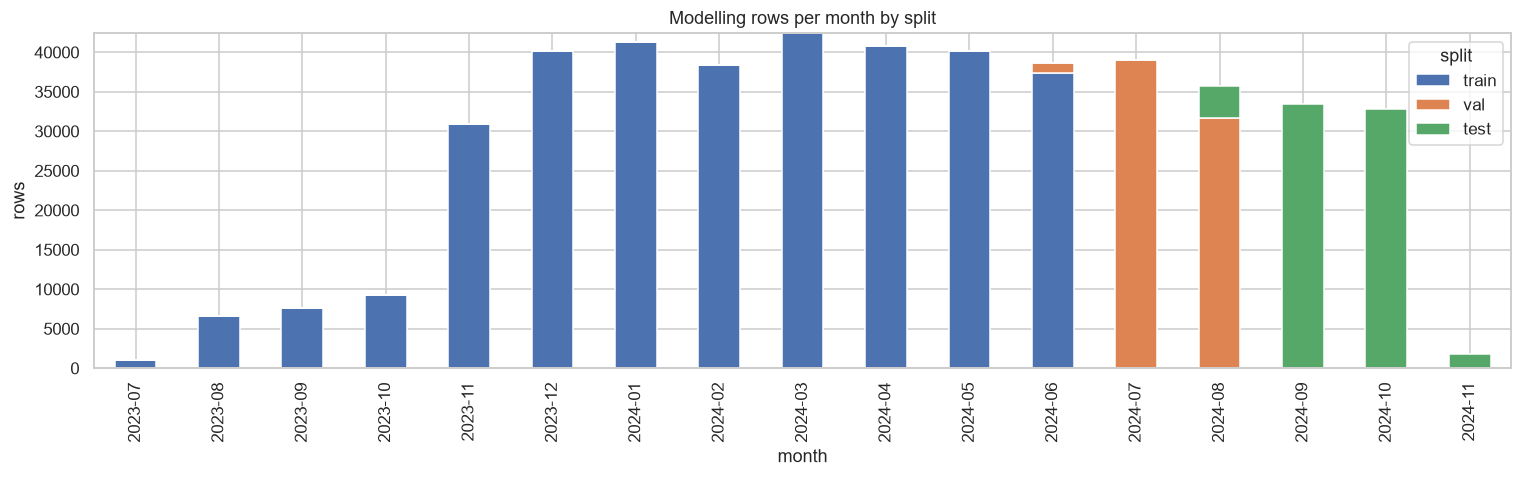

In [4]:
timeline = pd.concat([
    train[[TIME_COL, TARGET]].assign(split="train"),
    val[[TIME_COL, TARGET]].assign(split="val"),
    test[[TIME_COL, TARGET]].assign(split="test"),
])
timeline["month"] = timeline[TIME_COL].dt.to_period("M").astype(str)
counts = timeline.groupby(["month", "split"]).size().unstack(fill_value=0)
counts = counts[["train", "val", "test"]]
counts.plot(kind="bar", stacked=True, figsize=(14, 4.5),
            color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Modelling rows per month by split")
plt.xlabel("month")
plt.ylabel("rows")
plt.legend(title="split")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_rows_by_month_split.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 23 - Target distribution per split (class-balance analogue)

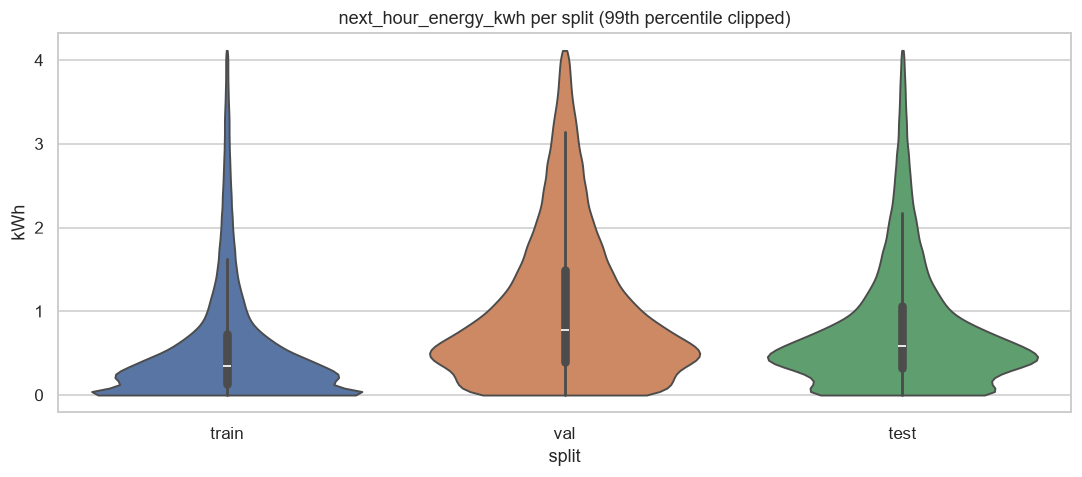

In [5]:
plot_df = timeline[timeline[TARGET] < timeline[TARGET].quantile(0.99)]
plt.figure(figsize=(10, 4.5))
sns.violinplot(data=plot_df, x="split", y=TARGET, order=["train", "val", "test"],
               hue="split", palette=["#4C72B0", "#DD8452", "#55A868"],
               legend=False, cut=0)
plt.title("next_hour_energy_kwh per split (99th percentile clipped)")
plt.xlabel("split")
plt.ylabel("kWh")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_target_distribution_by_split.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 24 - Household coverage over time

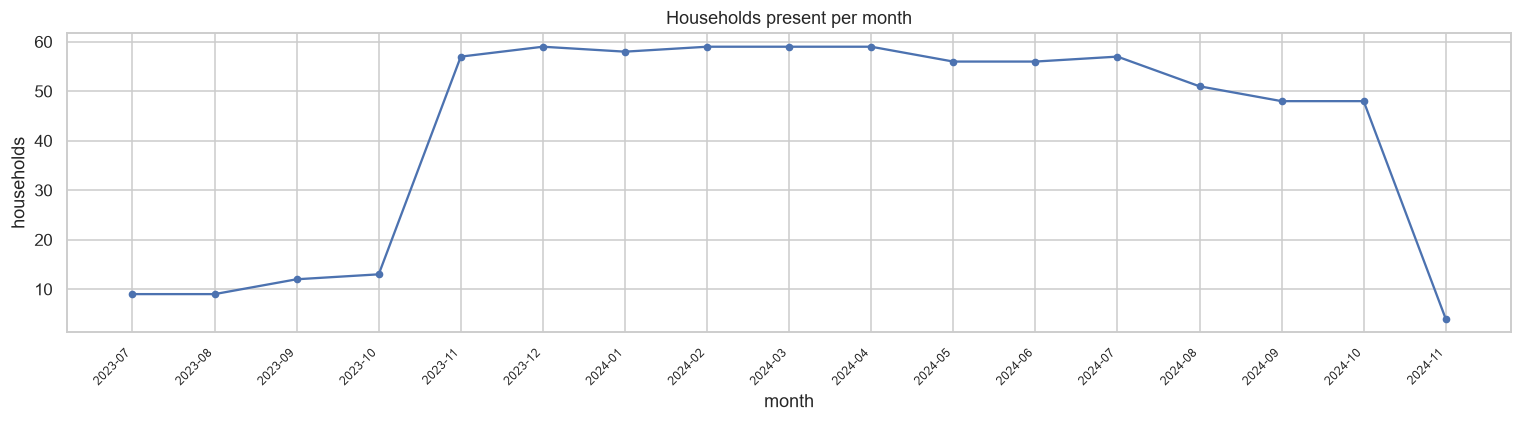

In [6]:
houses = pd.concat([
    train[[TIME_COL, HOUSE_COL]], val[[TIME_COL, HOUSE_COL]], test[[TIME_COL, HOUSE_COL]],
])
houses["month"] = houses[TIME_COL].dt.to_period("M").astype(str)
cov = houses.groupby("month")[HOUSE_COL].nunique()
plt.figure(figsize=(14, 4))
plt.plot(range(len(cov)), cov.to_numpy(), marker="o", ms=4, color="#4C72B0")
plt.xticks(range(len(cov)), cov.index, rotation=45, ha="right", fontsize=8)
plt.title("Households present per month")
plt.xlabel("month")
plt.ylabel("households")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_houses_per_month.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 25 - Monthly mean target with split boundaries

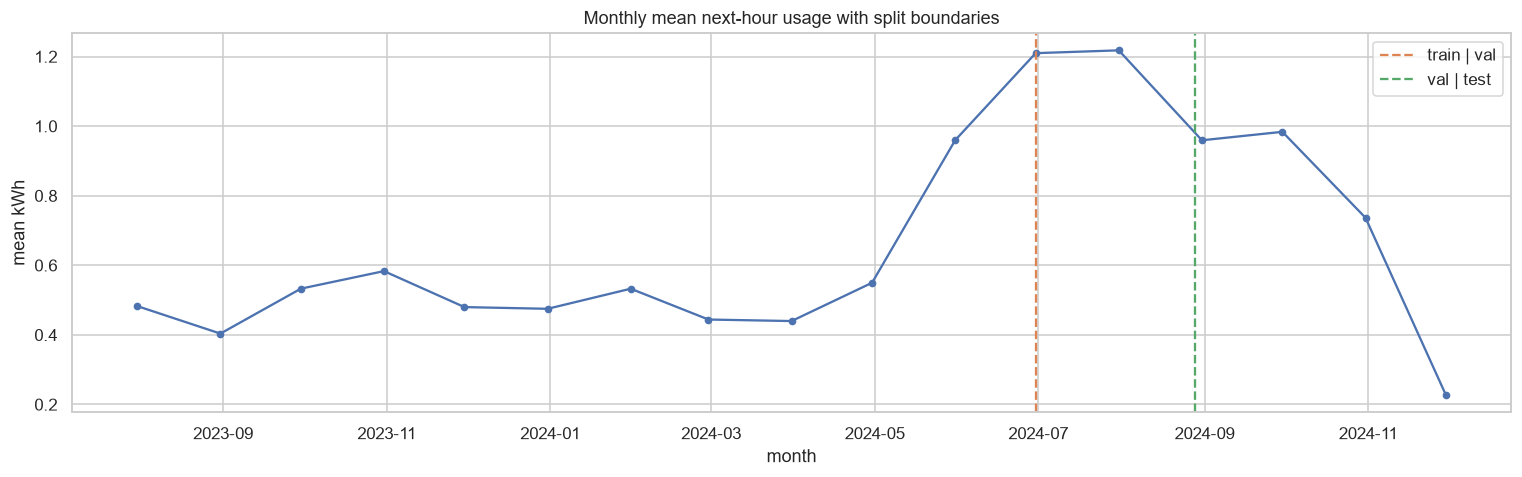

In [7]:
monthly = features.set_index(TIME_COL)[TARGET].resample("ME").mean()
val_start = pd.Timestamp(summary["boundaries"]["val_start"])
test_start = pd.Timestamp(summary["boundaries"]["test_start"])
plt.figure(figsize=(14, 4.5))
plt.plot(monthly.index, monthly.to_numpy(), marker="o", ms=4, color="#4C72B0")
plt.axvline(val_start, color="#DD8452", ls="--", label="train | val")
plt.axvline(test_start, color="#55A868", ls="--", label="val | test")
plt.title("Monthly mean next-hour usage with split boundaries")
plt.xlabel("month")
plt.ylabel("mean kWh")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_monthly_target_with_boundaries.png", dpi=220, bbox_inches="tight")
plt.show()

## 3. Leak-free pipeline (feature engineering + transforms)

Three steps, all fitted on `train` only:

1. `FeatureEngineer` - calendar features and wind-direction sin/cos from raw inputs (stateless).
2. `ColumnTransformer` - median-impute + standardise numeric; mode-impute + one-hot encode categorical.
3. The estimator (not fitted in this notebook; Phase 4 does that inside each CV fold).

Validation and test are only transformed, never fitted.

In [8]:
prep, X_train, y_train, X_val, y_val, X_test, y_test = fit_on_train(train, val, test)
print("X_train", X_train.shape, "| y_train", y_train.shape)
print("X_val  ", X_val.shape, "| y_val  ", y_val.shape)
print("X_test ", X_test.shape, "| y_test ", y_test.shape)
print("pipeline steps:", list(prep.named_steps))
names = get_feature_names(prep)
print("transformed features:", len(names))
print(names[:6], "...", names[-8:])

X_train (336053, 49) | y_train (336053,)
X_val   (71995, 49) | y_val   (71995,)
X_test  (72059, 49) | y_test  (72059,)
pipeline steps: ['features', 'preprocess']
transformed features: 49
['temperature', 'humidity', 'dew', 'precipitation', 'wind_speed', 'wind_direction'] ... ['city_Karachi', 'city_Lahore', 'city_Multan', 'city_Peshawar', 'city_Skardu', 'Owner/Rented_Owner', 'Owner/Rented_Rented', 'Owner/Rented_Residing as tenant']


In [9]:
# Scaler statistics must come from the IMPUTED, ENGINEERED training data only.
column_pre = prep.named_steps["preprocess"]
scaler = column_pre.named_transformers_["num"].named_steps["scaler"]
imputer = column_pre.named_transformers_["num"].named_steps["imputer"]

engineered_train = prep.named_steps["features"].transform(train[INPUT_COLUMNS])
expected = imputer.transform(engineered_train[NUMERIC_FEATURES]).mean(axis=0)
assert np.allclose(scaler.mean_, expected, atol=1e-8)

engineered_all = prep.named_steps["features"].transform(
    pd.concat([train, val, test])[INPUT_COLUMNS]
)
full_mean = np.nanmean(engineered_all[NUMERIC_FEATURES].to_numpy(), axis=0)
drift = float(np.max(np.abs(scaler.mean_ - full_mean)))
print("scaler fitted on train only: OK")
print(f"max drift vs full-data mean: {drift:.3f} (proves val/test were not used)")
print("NaNs after transform: train", int(np.isnan(X_train).sum()),
      "| val", int(np.isnan(X_val).sum()),
      "| test", int(np.isnan(X_test).sum()))
assert not np.isnan(X_train).any() and not np.isnan(X_val).any() and not np.isnan(X_test).any()

scaler fitted on train only: OK
max drift vs full-data mean: 8.779 (proves val/test were not used)
NaNs after transform: train 0 | val 0 | test 0


In [10]:
# Feature engineering really happens inside the pipeline: the raw frame contains
# no calendar columns and no wind-direction encoding.
raw_derived = [c for c in INPUT_COLUMNS if c in
               ("hour", "day_of_week", "month", "is_weekend", "wind_dir_sin", "wind_dir_cos")]
print("derived feature columns present in raw input:", raw_derived)
derived = prep.named_steps["features"].transform(val[INPUT_COLUMNS].head(3))
derived[["hour", "day_of_week", "month", "is_weekend", "wind_dir_sin", "wind_dir_cos"]]

derived feature columns present in raw input: []


,hour,day_of_week,month,is_weekend,wind_dir_sin,wind_dir_cos
336108,1,6,6,1,0.573576,-0.819152
336109,1,6,6,1,0.788011,-0.615661
336110,1,6,6,1,0.788011,-0.615661


## 4. Split integrity checks

In [11]:
assert train[TIME_COL].max() < val[TIME_COL].min() < test[TIME_COL].min()
assert train[TIME_COL].max() + pd.Timedelta(hours=1) < pd.Timestamp(summary["boundaries"]["val_start"])
assert val[TIME_COL].max() + pd.Timedelta(hours=1) < pd.Timestamp(summary["boundaries"]["test_start"])
assert len(train) + len(val) + len(test) == len(features) - summary["rows_purged_at_boundaries"]
print("chronology, boundary purge and row accounting: OK")

chronology, boundary purge and row accounting: OK


## 5. Save split artifacts

In [12]:
paths = save_splits(train, val, test, summary)
for path in paths:
    print("saved ->", path)

saved -> D:\BijliCast\data\processed\splits\train.parquet
saved -> D:\BijliCast\data\processed\splits\val.parquet
saved -> D:\BijliCast\data\processed\splits\test.parquet
saved -> D:\BijliCast\data\processed\split_summary.json


## Findings - Notebook 07

- **Train 336,053 (69.98%) | Val 71,995 (14.99%) | Test 72,059 (15.01%)**.
- Train: Jul 2023 - Jun 2024, Val: Jun - Aug 2024, Test: Aug - Nov 2024.
- 102 boundary rows purged so no label crosses a split boundary.
- Household coverage thins late in the panel (59 -> 48 by September), which is expected from meter end-dates; the test split still contains ~72k rows.
- The pipeline produced **49 transformed columns** (42 features, with city/Owner-Rented one-hot encoded) and was fitted on training data only.
- Test remains untouched until the final evaluation in Phase 4.